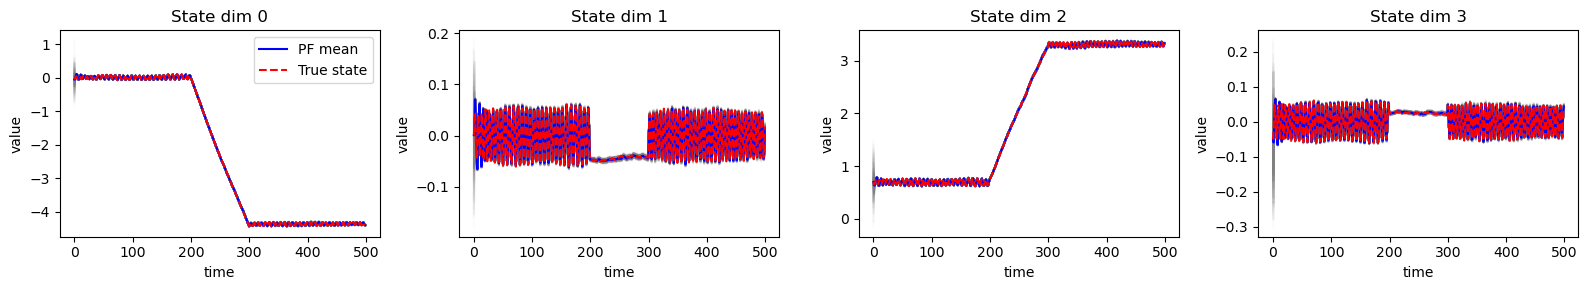

In [ ]:
import random
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt

# ============================
# Model definitions (D = 4)
# ============================

dt = 1.0
FCV = 1.0 * jnp.array([[1, dt, 0, 0],[0, 1, 0, 0],[0, 0, 1, dt],[0, 0, 0, 1]])
acc = 0.05

def Omega(x, acc):
    return acc / jnp.sqrt(x[1]**2 + x[3]**2 + 1e-12)

def FCT(x, a):
    om = Omega(x, a)
    s = jnp.sin(dt * om)
    c = jnp.cos(dt * om)
    om_safe = jnp.where(jnp.abs(om) < 1e-6, 1e-6, om)
    s_over_om = s / om_safe
    one_minus_c_over_om = (1.0 - c) / om_safe
    
    return jnp.array([[1, s_over_om, 0, -one_minus_c_over_om],
                      [0, c, 0, -s],
                      [0, one_minus_c_over_om, 1, s_over_om],
                      [0, s, 0, c]])

G = jnp.array([[0.5, 0],[1, 0],[0, 0.5],[0, 1]])

# dynamics: x_t = f(x_{t-1}, q_t, u_t)
f = lambda x, q, u, dyn_params: (
    (0.5 * (u - 1) * (u - 2) * FCV
     - u * (u - 2) * FCT(x, acc)
     + 0.5 * u * (u - 1) * FCT(x, -acc)) @ x
    + G @ q
)

# emission mean h(x, u)
def h(x, u, em_params):
    return jnp.array([
        jnp.arctan2(x[2], x[0]),
        jnp.sqrt(x[0] ** 2 + x[2] ** 2 + 1e-12),
    ])

# y_t = g(x_t, r_t, u_t) = h(x_t, u_t) + r_t
g = lambda x, r, u, em_params: h(x, u, em_params) + r


# ============================
# Bootstrap particle filter
# ============================

def multinomial_resample(key, weights):

    N = weights.shape[0]

    return jr.choice(key, N, shape=(N,), p=weights)

def bootstrap_filter(
    key,
    y_seq,
    u_seq,
    N,
    init_sampler,
    transition_fn,
    log_likelihood_fn,
    dyn_params,
    em_params,
):
    T = y_seq.shape[0]

    # ---------- t = 0 ----------
    key, k_init = jr.split(key)
    particles = init_sampler(k_init, N, dyn_params)   # (N, 4)
    y0 = y_seq[0]
    u0 = u_seq[0]

    log_w = jax.vmap(lambda x: log_likelihood_fn(y0, x, u0, em_params))(particles)
    log_w = log_w - jax.scipy.special.logsumexp(log_w)
    w = jnp.exp(log_w)

    particles_hist = [particles]
    weights_hist = [w]

    # ---------- t >= 1 ----------
    for t in range(1, T):
        y_t = y_seq[t]
        u_t = u_seq[t]

        key, k_res, k_trans = jr.split(key, 3)
        idx = multinomial_resample(k_res, w)
        anc = particles[idx]

        keys_trans = jr.split(k_trans, N)
        particles = jax.vmap(
            lambda k, x: transition_fn(k, x, u_t, dyn_params)
        )(keys_trans, anc)

        log_w = jax.vmap(lambda x: log_likelihood_fn(y_t, x, u_t, em_params))(particles)
        log_w = log_w - jax.scipy.special.logsumexp(log_w)
        w = jnp.exp(log_w)

        particles_hist.append(particles)
        weights_hist.append(w)

    particles_hist = jnp.stack(particles_hist, axis=0)  # (T, N, 4)
    weights_hist = jnp.stack(weights_hist, axis=0)      # (T, N)

    return particles_hist, weights_hist


# ============================
# Model-specific functions
# ============================

def init_sampler(key, N, dyn_params):
    mu0 = dyn_params["mu0"]          # (4,)
    Sigma0 = dyn_params["Sigma0"]    # (4,4)
    L = jnp.linalg.cholesky(Sigma0)
    z = jr.normal(key, (N, 4))
    return mu0 + z @ L.T

def transition_fn(key, x_prev, u_t, dyn_params):
    q_std = dyn_params["q_std"]      # (2,)
    eps = jr.normal(key, (2,))
    q = q_std * eps
    return f(x_prev, q, u_t, dyn_params)

def log_likelihood_fn(y_t, x_t, u_t, em_params):
    r_std = em_params["r_std"]       # (2,)
    mean = h(x_t, u_t, em_params)
    diff = y_t - mean
    var = r_std ** 2
    log_norm = jnp.sum(0.5 * jnp.log(2 * jnp.pi * var))
    return -0.5 * jnp.sum(diff ** 2 / var) - log_norm


# ============================
# Simulate one trajectory, T = 500
# ============================

key = jr.PRNGKey(12312)
T = 500
D = 4

# inputs schedule
inputs = jnp.array([1] * int(2 * T / 5) + [0] * int(T / 5) + [2] * int(2 * T / 5))
u_seq = inputs  # (T,)

dyn_params = {
    "mu0":  1.0 * jnp.array([-0.05, 0.001, 0.7, -0.05]),
    "Sigma0": 1.0 * jnp.array([[0.1, 0.0, 0.0, 0.0],
                                          [0.0, 0.005, 0.0, 0.0],
                                          [0.0, 0.0, 0.1, 0.0],
                                          [0.0, 0.0, 0.0, 0.01]]),
    "q_std": 1e-3,
}
em_params = {
    "r_std": 5 * 1e-3,
}

x_true = []
y_seq = []
# initial state
x0 = dyn_params["mu0"]
x_true.append(x0)

key, kx, ky = jr.split(key, 3)

# simulate states
for t in range(1, T):
    kx, sub = jr.split(kx)
    eps_q = jr.normal(sub, (2,))
    q = dyn_params["q_std"] * eps_q
    x_next = f(x_true[-1], q, u_seq[t], dyn_params)
    x_true.append(x_next)

x_true = jnp.stack(x_true, axis=0)  # (T, 4)

# simulate observations
for t in range(T):
    ky, sub = jr.split(ky)
    eps_r = jr.normal(sub, (2,))
    r = em_params["r_std"] * eps_r
    y = g(x_true[t], r, u_seq[t], em_params)
    y_seq.append(y)

y_seq = jnp.stack(y_seq, axis=0)  # (T, 2)


# ============================
# Run particle filter
# ============================

N_particles = 100000  # you can increase, but plotting gets heavy
key_pf = jr.PRNGKey(random.randint(key, (), 0, 1e6))

particles_hist, weights_hist = bootstrap_filter(
    key_pf,
    y_seq,
    u_seq,
    N_particles,
    init_sampler,
    transition_fn,
    log_likelihood_fn,
    dyn_params,
    em_params,
)


# ============================
# Plot particles vs true states
# ============================

def plot_particles_vs_truth(particles_hist, true_states):
    import numpy as np

    T, N, D = particles_hist.shape
    t_axis = np.arange(T)
    ph = np.array(particles_hist)
    xs = np.array(true_states)

    fig, axes = plt.subplots(1, D, figsize=(4 * D, 3), sharex=True)

    if D == 1:
        axes = [axes]

    # optionally subsample particles for plotting to avoid overplotting
    max_plot_particles = min(N, 200)
    idx_sub = np.linspace(0, N - 1, max_plot_particles).astype(int)

    for d in range(D):
        ax = axes[d]
        # particle trajectories
        for n in idx_sub:
            ax.plot(t_axis, ph[:, n, d], color="gray", alpha=0.03)

        # PF mean
        pf_mean = ph[:, :, d].mean(axis=1)
        ax.plot(t_axis, pf_mean, color="blue", label="PF mean")

        # true state
        ax.plot(t_axis, xs[:, d], "r--", label="True state")

        ax.set_title(f"State dim {d}")
        ax.set_xlabel("time")
        ax.set_ylabel("value")
        if d == 0:
            ax.legend() 

    plt.tight_layout()
    plt.show()

plot_particles_vs_truth(particles_hist, x_true)

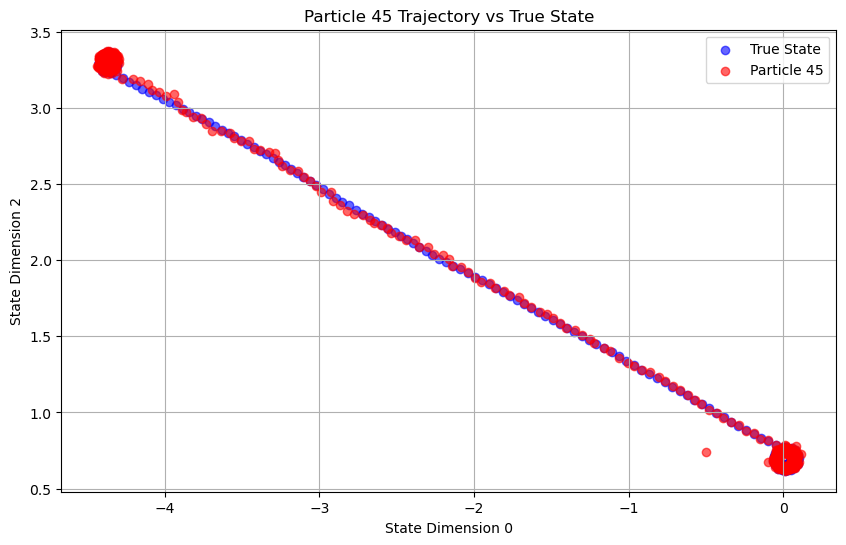

In [6]:
# plot a single particle trajectory p vs true states in two dimensional scatter plot

p = 45
dims = (0, 2)  # plot state components 0 and 2 (x and z positions)
T, N, D = particles_hist.shape

ph = np.array(particles_hist)   # (T, N, D)
truth = np.array(x_true)        # (T, D)
t_axis = np.arange(T)

plt.figure(figsize=(10, 6))
plt.scatter(truth[:, dims[0]], truth[:, dims[1]], c='blue', label='True State', alpha=0.6)
plt.scatter(ph[:, p, dims[0]], ph[:, p, dims[1]], c='red', label=f'Particle {p}', alpha=0.6)
plt.title(f'Particle {p} Trajectory vs True State')
plt.xlabel(f'State Dimension {dims[0]}')
plt.ylabel(f'State Dimension {dims[1]}')
plt.legend()
plt.grid()
plt.show()

In [9]:
import numpy as np

import jax
import jax.numpy as jnp

def particle_degeneracy(particles: jnp.ndarray, rtol=1e-5, atol=1e-8):
    """
    particles: array (n_prt, T, d)
    returns: int32 array (T,) with #distinct states per timestep (allclose-based)
    """
    def count_unique_t(x_t):
        # x_t: (n_prt, d)
        diff = jnp.abs(x_t[:, None, :] - x_t[None, :, :])                # (n, n, d)
        thresh = atol + rtol * jnp.abs(x_t[None, :, :])                 # (n, n, d)
        close = jnp.all(diff <= thresh, axis=-1)                        # (n, n)
        prior_close = jnp.tril(close, k=-1).any(axis=1)                 # (n,)
        return (~prior_close).sum(dtype=jnp.int32)                      # scalar

    return jax.vmap(count_unique_t, in_axes=1)(particles)               # (T,)

# Example:
# particles = particles_hist.transpose(1, 0, 2)  # to shape (n_prt, T, d)
# counts = particle_degeneracy_allclose_jax(particles)

particles = particles_hist.transpose(1, 0, 2)  # shape (N, T, D)
counts = particle_degeneracy(particles)
plt.figure(figsize=(10,4))
plt.plot(counts, label='Distinct particles per timestep')
plt.xlabel('Time step')
plt.ylabel('# distinct states')
plt.title('Particle degeneracy')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

: 